
### Database Connection Setup

The original `olympics_db.py` file contains local PostgreSQL connection
configuration and is intentionally excluded from this repository to
protect credentials.

The analysis notebook was developed using a local PostgreSQL database
named `olympics_db`. The helper functions used for querying the database
are part of the local development setup.

To reproduce the analysis, configure your own PostgreSQL connection
and define the required helper functions before running the query cells.


In [2]:
import pandas as pd
from olympics_db import engine, sql, peek, columns, common_columns, sql_with_print

In [ ]:
%pip install ipykernel

In [ ]:
%matplotlib inline

In [4]:
schemas = sql("""
SELECT DISTINCT table_schema
FROM information_schema.tables
WHERE table_schema NOT IN ('pg_catalog', 'information_schema')
ORDER BY table_schema;
""")["table_schema"].tolist()


for schema in schemas:

    tables = sql(f"""
    SELECT table_name
    FROM information_schema.tables
    WHERE table_schema = '{schema}'
    ORDER BY table_name;
    """)

    for table in tables["table_name"]:

        # ============================================================
        # BASIC TABLE INFORMATION
        # ============================================================

        cnt = sql(f"""
            SELECT COUNT(*) AS rows
            FROM "{schema}"."{table}";
        """)

        total_rows = int(cnt.iloc[0, 0])

        columns = sql(f"""
            SELECT
                ordinal_position,
                column_name,
                data_type
            FROM information_schema.columns
            WHERE table_schema = '{schema}'
              AND table_name = '{table}'
            ORDER BY ordinal_position;
        """)

        print("=" * 100)
        print(f"Schema : {schema}")
        print(f"Table  : {table}")
        print(f"Rows   : {total_rows:,}")
        print("-" * 100)

        print("COLUMNS")
        print("-" * 100)

        for _, row in columns.iterrows():

            print(
                f"{int(row['ordinal_position']):>2}. "
                f"{row['column_name']:<35} "
                f"{row['data_type']}"
            )

        # ============================================================
        # STATISTICS
        # ============================================================

        print("\nSTATISTICS")
        print("-" * 100)

        for _, row in columns.iterrows():

            column = row["column_name"]
            data_type = row["data_type"]

            # ========================================================
            # NUMERIC
            # ========================================================

            if data_type in [
                "smallint",
                "integer",
                "bigint",
                "numeric",
                "decimal",
                "real",
                "double precision"
            ]:

                stats = sql(f"""
                    SELECT
                        COUNT("{column}") AS count,
                        COUNT(*) - COUNT("{column}") AS null_count,
                        COUNT(DISTINCT "{column}") AS distinct_count,
                        MIN("{column}") AS min_value,
                        MAX("{column}") AS max_value,
                        AVG("{column}"::numeric) AS avg_value,
                        PERCENTILE_CONT(0.5)
                            WITHIN GROUP (ORDER BY "{column}") AS median,
                        STDDEV("{column}"::numeric) AS stddev
                    FROM "{schema}"."{table}";
                """)

                s = stats.iloc[0]

                print(f"\nColumn: {column}")
                print(f"Type  : {data_type}")
                print(f"Count : {int(s['count']):,}")
                print(f"NULLs : {int(s['null_count']):,}")
                print(f"Distinct: {int(s['distinct_count']):,}")
                print(f"Min   : {s['min_value']}")
                print(f"Max   : {s['max_value']}")
                print(f"Mean  : {s['avg_value']}")
                print(f"Median: {s['median']}")
                print(f"Stddev: {s['stddev']}")

            # ========================================================
            # DATE / TIMESTAMP
            # ========================================================

            elif data_type in [
                "date",
                "timestamp without time zone",
                "timestamp with time zone"
            ]:

                stats = sql(f"""
                    SELECT
                        COUNT("{column}") AS count,
                        COUNT(*) - COUNT("{column}") AS null_count,
                        COUNT(DISTINCT "{column}") AS distinct_count,
                        MIN("{column}") AS min_value,
                        MAX("{column}") AS max_value
                    FROM "{schema}"."{table}";
                """)

                s = stats.iloc[0]

                print(f"\nColumn: {column}")
                print(f"Type  : {data_type}")
                print(f"Count : {int(s['count']):,}")
                print(f"NULLs : {int(s['null_count']):,}")
                print(f"Distinct: {int(s['distinct_count']):,}")
                print(f"Min   : {s['min_value']}")
                print(f"Max   : {s['max_value']}")

            # ========================================================
            # BOOLEAN
            # ========================================================

            elif data_type == "boolean":

                stats = sql(f"""
                    SELECT
                        COUNT("{column}") AS count,
                        COUNT(*) - COUNT("{column}") AS null_count,
                        COUNT(DISTINCT "{column}") AS distinct_count,
                        COUNT(*) FILTER (
                            WHERE "{column}" = TRUE
                        ) AS true_count,
                        COUNT(*) FILTER (
                            WHERE "{column}" = FALSE
                        ) AS false_count
                    FROM "{schema}"."{table}";
                """)

                s = stats.iloc[0]

                print(f"\nColumn: {column}")
                print(f"Type  : {data_type}")
                print(f"Count : {int(s['count']):,}")
                print(f"NULLs : {int(s['null_count']):,}")
                print(f"Distinct: {int(s['distinct_count']):,}")
                print(f"TRUE  : {int(s['true_count']):,}")
                print(f"FALSE : {int(s['false_count']):,}")

            # ========================================================
            # JSON / JSONB
            # ========================================================

            elif data_type in ["json", "jsonb"]:

                stats = sql(f"""
                    SELECT
                        COUNT("{column}") AS count,
                        COUNT(*) - COUNT("{column}") AS null_count,
                        COUNT(DISTINCT "{column}"::text) AS distinct_count
                    FROM "{schema}"."{table}";
                """)

                examples = sql(f"""
                    SELECT "{column}"
                    FROM "{schema}"."{table}"
                    WHERE "{column}" IS NOT NULL
                    LIMIT 5;
                """)

                s = stats.iloc[0]

                print(f"\nColumn: {column}")
                print(f"Type  : {data_type}")
                print(f"Count : {int(s['count']):,}")
                print(f"NULLs : {int(s['null_count']):,}")
                print(f"Distinct: {int(s['distinct_count']):,}")

                print("Examples:")

                for value in examples[column].tolist():
                    print(f"  {value}")

            # ========================================================
            # TEXT / VARCHAR / CHAR
            # ========================================================

            else:

                stats = sql(f"""
                    SELECT
                        COUNT("{column}") AS count,
                        COUNT(*) - COUNT("{column}") AS null_count,
                        COUNT(DISTINCT "{column}") AS distinct_count,
                        MIN(LENGTH("{column}")) AS min_length,
                        MAX(LENGTH("{column}")) AS max_length,
                        AVG(LENGTH("{column}")) AS avg_length
                    FROM "{schema}"."{table}";
                """)

                examples = sql(f"""
                    SELECT DISTINCT "{column}"
                    FROM "{schema}"."{table}"
                    WHERE "{column}" IS NOT NULL
                    LIMIT 5;
                """)

                s = stats.iloc[0]

                print(f"\nColumn: {column}")
                print(f"Type  : {data_type}")
                print(f"Count : {int(s['count']):,}")
                print(f"NULLs : {int(s['null_count']):,}")
                print(f"Distinct: {int(s['distinct_count']):,}")
                print(f"Min length: {s['min_length']}")
                print(f"Max length: {s['max_length']}")
                print(f"Avg length: {s['avg_length']}")

                print("Examples:")

                for value in examples[column].tolist():
                    print(f"  {value}")

        print("\n")

Schema : public
Table  : city
Rows   : 42
----------------------------------------------------------------------------------------------------
COLUMNS
----------------------------------------------------------------------------------------------------
 1. id                                  integer
 2. city_name                           character varying

STATISTICS
----------------------------------------------------------------------------------------------------

Column: id
Type  : integer
Count : 42
NULLs : 0
Distinct: 42
Min   : 1.0
Max   : 42.0
Mean  : 21.5
Median: 21.5
Stddev: 12.267844146385297

Column: city_name
Type  : character varying
Count : 42
NULLs : 0
Distinct: 42
Min length: 4.0
Max length: 22.0
Avg length: 8.619047619047619
Examples:
  Sydney
  St. Louis
  Albertville
  Montreal
  Sapporo


Schema : public
Table  : competitor_event
Rows   : 260,971
----------------------------------------------------------------------------------------------------
COLUMNS
-----------

In [162]:
# # Set 1 — Basic Queries (10 Questions)

# # Q01. Return all Olympic Games ordered by year in ascending order.
# # Tables: games
# sql("""
# select * from games order by games_year asc;
# """)

# # Q02. Return the total number of athletes, along with the number of male and female athletes.
# # Tables: person
# sql("""
# with ft as (select gender, count(id) as gender_count from person group by gender)
# select *, (sum(gender_count) over ())::int as total_count from ft;
# """)

# # Q03. Return the total number of Olympic Games, distinct Olympic years, and distinct seasons.
# # Tables: games
# sql("""
# select count(id) as no_of_years, count(distinct games_year) as distict_year, count(distinct season) as distinct_season from games;
# """)

# # Q04. Return the number of athletes whose height is greater than 190 cm, along with their average weight.
# # Tables: person
# sql("""
# select count(id) as gth, avg(weight) as avg_weight from person where height > 190;
# """)

# # Q05. Return each gender with the total number of athletes and their average height and weight, excluding records where height or weight is zero.
# # Tables: person
# sql("""
# with ft as (select * from person where height != 0 and weight != 0)
# select gender, count(id) as no_of_athletes, avg(height) as avg_height, avg(weight) as avg_weight from ft group by gender;
# """)

## Another approach maybe

# sql("""
# with ft as (select *, case
# when height != 0 then height
# end as heights,
# case when weight != 0 then weight
# end as weights
# from person),

# ft1 as (select *, case when heights is not null and weights is not null then 1 end as non_nulls from ft)

# select gender, count(non_nulls) as no_of_athletes, avg(heights) as avg_height, avg(weights) as avg_weight from ft1 group by gender;
# """)

# # Q06. Return each Olympic season with the number of Games and the earliest and latest year in which that season was held.
# # Tables: games
# sql("""
# select season, count(id) as no_of_games, min(games_year) as min_year, max(games_year) as max_year from games group by season;
# """)

# # Q07. Return the top 10 sports with the highest number of events.
# # Tables: sport, event
# sql("""
# with ft as (select e.*, s.sport_name from event e join sport s on s.id = e.sport_id)
# select sport_name, count(event_name) as no_of_sports from ft group by sport_name order by no_of_sports desc limit 10;
# """)

# # Q08. Return each medal type with its total number of records in the competitor_event table.
# # Tables: medal, competitor_event
# sql("""
# with all_medals as (select id, coalesce(medal_name, 'No Medal') as medal_name from medal)

# select a.medal_name, count(c.event_id) as mcount from all_medals a join competitor_event c on a.id = c.medal_id group by a.medal_name;
# """)

# # Q09. Return the top 10 countries or regions with the highest number of athletes.
# # Tables: person_region, noc_region, person
# sql("""
# with ft as (select region_id, count(person_id) as no_of_people from person_region group by region_id)
# select n.region_name, f.no_of_people from noc_region n join ft f on f.region_id = n.id order by f.no_of_people desc limit 10;
# """)

# # Q10. Return each Olympic host city with the number of Olympic Games hosted, ordered from highest to lowest.
# # Tables: city, games_city, games
# sql("""
# with ft as (select city_id, count(games_id) as no_of_games from games_city group by city_id order by count(games_id) desc)
# select c.city_name, f.no_of_games from city c join ft f on f.city_id = c.id order by f.no_of_games desc;
# """)

# # Set 2 — Intermediate Queries (10 Questions)

# # Q11. Return each Olympic year and season with the total number of athletes who participated in that edition.
# # Tables: games, games_competitor, person
# sql("""
# with ft as (select g1.*, g2.games_name from games_competitor g1 join games g2 on g2.id = g1.games_id)

# select games_name, count(person_id) as no_of_players from ft group by games_name order by count(person_id) desc;
# """)

# # Q12. Return each sport with the total number of athletes who participated across all Olympic Games, counting each athlete only once per sport.
# # Tables: sport, event, competitor_event, games_competitor, person
# sql("""
# with ft as (select e.id as event_id, e.sport_id, e.event_name, s.sport_name from event e join sport s on s.id = e.sport_id),

# ft2 as (select f.*, c.* from competitor_event c join ft f on f.event_id = c.event_id),

# ft3 as (select f2.*, g.* from games_competitor g join ft2 f2 on f2.competitor_id = g.id)

# select sport_name, count(distinct person_id) as no_of_participants from ft3 group by sport_name;
# """)

# # Q13. Return each country or region with its total gold, silver, and bronze medals, along with its total medals, ordered by total medals in descending order.
# # Tables: noc_region, person_region, person, competitor_event, medal, event, sport
# sql("""
# with ft as (select p.region_id, p.person_id, n.noc, n.region_name from noc_region n join person_region p on p.region_id = n.id),

# ft2 as (select gc.id as competitor_id, gc.games_id, gc.person_id from games_competitor gc join person p on p.id = gc.person_id),

# ft3 as (select f.*, c.*, coalesce(m.medal_name, 'Not Available') as medal_name from ft2 f join competitor_event c on f.competitor_id = c.competitor_id join medal m on m.id = c.medal_id),

# ft4 as (select f.event_id, f.medal_name, p.*, n.region_name from ft3 f join person_region p on p.person_id = f.person_id join noc_region n on n.id = p.region_id)

# select region_name, medal_name, count(person_id) as cnt from ft4 group by region_name, medal_name order by count(person_id) desc;
# """)

# # Q14. Return the top 10 athletes with the highest total number of medals, including their full name, gender, country or region, and gold, silver, and bronze medal counts.
# # Tables: person, person_region, noc_region, competitor_event, medal
# sql("""
# with ft as (select c.event_id, c.medal_id, c.competitor_id, g.person_id, p.full_name, m.medal_name from competitor_event c join games_competitor g on g.id = c.competitor_id join person p on p.id = g.person_id join medal m on m.id = c.medal_id),

# person_medals as (select * from ft where medal_name is not null),

# temp as (select person_id, full_name, medal_name, count(competitor_id) as medal_count from person_medals group by person_id, full_name, medal_name),

# t10 as (select *, (sum(medal_count) over (partition by person_id))::int as overall_count from temp),

# top10 as (select *, row_number() over (order by overall_count desc) as rn from t10)

# select * from top10 where rn <= 10 order by medal_count desc
# """)

# # Q15. Return each Olympic Games edition with its total participants, average participant age, youngest participant age, and oldest participant age.
# # Tables: games, games_competitor, person
# sql("""
# with ft as (select g.games_name, gc.age, gc.person_id from games g left join games_competitor gc on gc.games_id = g.id)

# select games_name, count(person_id) as season_count, avg(age) as avg_age, min(age) as youngest_age, max(age) as oldest_age from ft group by games_name;
# """)

# # Q16. Return each sport with the number of distinct events and the total number of competitor-event entries, ordered by the highest number of entries.
# # Tables: sport, event, competitor_event
# sql("""
# with es as (select e.id as event_id, e.event_name, e.sport_id, e.event_name, s.sport_name from event e join sport s on s.id = e.sport_id),

# je as (select event_id, count(competitor_id) as event_cnt from competitor_event group by event_id),

# ft as (select e.*, j.event_cnt from es e join je j on j.event_id = e.event_id)

# select sport_name, count(distinct event_id) as distinct_events, sum(event_cnt)::int as total_ce from ft group by sport_name order by sum(event_cnt)::int desc;
# """)

# # Q17. Return each country or region with the number of distinct Olympic Games editions in which its athletes participated, along with the earliest and latest participation years.
# # Tables: noc_region, person_region, games_competitor, games
# sql("""
# with regions as (select p.person_id, n.region_name, n.id as region_id from person_region p join noc_region n on n.id = p.region_id),

# gce as (select gc.id as competitor_id, ce.event_id, gc.person_id from games_competitor gc join competitor_event ce on ce.competitor_id = gc.id),

# ft as (select r.region_name, g.*, r.region_id from regions r join gce g on g.person_id = r.person_id),

# ft2 as (select f.*, gc.games_id, g.games_year from ft f join games_competitor gc on gc.id = f.competitor_id join games g on g.id = gc.games_id)

# select region_name, count(distinct games_id) as dc, min(games_year) as min_year, max(games_year) as max_year from ft2 group by region_name;
# """)

# # Q18. Return the top 5 sports with the highest average athlete age, considering only athletes with a valid age between 10 and 80, and include the number of distinct athletes in each sport.
# # Tables: sport, event, competitor_event, games_competitor, person
# sql("""
# with ft as (select e.sport_id, s.sport_name, e.event_name, c.competitor_id, g.age from sport s join event e on e.sport_id = s.id join competitor_event c on c.event_id = e.id join games_competitor g on g.id = c.competitor_id),

# valid as (select * from ft where age between 10 and 80)

# select sport_name, avg(age) as avg_age from valid group by sport_name order by avg_age desc limit 5;
# """)

# # Q19. Return each Olympic Games edition with its total medal count and the percentage contribution of gold, silver, and bronze medals to that edition's total medals.
# # Tables: games, games_competitor, competitor_event, medal
# sql("""
# with ft as (select c.competitor_id, m.medal_name, g.games_name from competitor_event c join medal m on m.id = c.medal_id join games_competitor gc on gc.id = c.competitor_id join games g on gc.games_id = g.id),


# ft1 as (select games_name, medal_name, count(*) as cat_cnt from ft group by games_name, medal_name order by games_name),

# ft2 as (select *, (sum(cat_cnt) over (partition by games_name))::int as total_cnt from ft1)

# select games_name, coalesce(medal_name, 'NA') as medal_name, ((cat_cnt::numeric/total_cnt)*100) as percentage_per_category from ft2;
# """)

# # Q20. Return the top 5 athletes by total medal count within each sport, including athlete name, sport, total medals, and medal breakdown by type. Use a window function to rank athletes within each sport.
# # Tables: person, games_competitor, competitor_event, medal, event, sport
# Q20. Return the top 5 athletes by total medal count within each sport, including athlete name, sport, total medals, and medal breakdown by type. Use a window function to rank athletes within each sport.
# Tables: person, games_competitor, competitor_event, medal, event, sport
sql("""
with pgc as (
    select
        p.id as person_id,
        p.full_name,
        gc.id as competitor_id
    from person p
    join games_competitor gc
        on gc.person_id = p.id
),

ceme as (
    select
        c.event_id,
        c.competitor_id,
        m.medal_name
    from competitor_event c
    join medal m
        on m.id = c.medal_id
    where m.medal_name is not null
),

es as (
    select
        e.id as event_id,
        s.sport_name
    from event e
    join sport s
        on s.id = e.sport_id
),

joined as (
    select
        p.person_id,
        p.full_name,
        e.sport_name,
        c.medal_name
    from es e
    join ceme c
        on c.event_id = e.event_id
    join pgc p
        on p.competitor_id = c.competitor_id
),

athlete_sport_medals as (
    select
        person_id,
        full_name,
        sport_name,
        count(*) as total_medals,
        count(*) filter (where medal_name = 'Gold') as gold_medals,
        count(*) filter (where medal_name = 'Silver') as silver_medals,
        count(*) filter (where medal_name = 'Bronze') as bronze_medals
    from joined
    group by person_id, full_name, sport_name
),

ranked as (
    select
        *,
        row_number() over (
            partition by sport_name
            order by total_medals desc, full_name asc, person_id
        ) as rn
    from athlete_sport_medals
)

select
    sport_name,
    person_id,
    full_name,
    total_medals,
    gold_medals,
    silver_medals,
    bronze_medals,
    rn as sport_rank
from ranked
where rn <= 5
order by sport_name, sport_rank;
""")

,sport_name,person_id,full_name,total_medals,gold_medals,silver_medals,bronze_medals,sport_rank
0,Aeronautics,107506,Hermann Schreiber,1,1,0,0,1
1,Alpine Skiing,20,Kjetil Andr Aamodt,8,4,2,2,1
2,Alpine Skiing,91797,Anja Sofia Tess Prson,6,1,1,4,2
3,Alpine Skiing,63093,Janica Kosteli,6,4,2,0,3
4,Alpine Skiing,79875,Samuel Bode Miller,6,1,3,2,4
...,...,...,...,...,...,...,...,...
313,Wrestling,28473,Wilfried Dietrich,5,1,2,2,1
314,Wrestling,57527,Aleksandr Aleksandrovich Karelin,4,3,1,0,2
315,Wrestling,118953,Artur Borisovich Taymazov,4,3,1,0,3
316,Wrestling,8793,Bruce Robert Baumgartner,4,2,1,1,4


In [163]:
# Analysis 01. How has athlete participation changed across Olympic Games editions?
# Tables: games, games_competitor
sql("""
SELECT
    g.games_year,
    g.season,
    g.games_name,
    COUNT(DISTINCT gc.person_id) AS total_athletes
FROM games g
JOIN games_competitor gc
    ON gc.games_id = g.id
GROUP BY
    g.games_year,
    g.season,
    g.games_name
ORDER BY
    g.games_year,
    g.season;
""")

,games_year,season,games_name,total_athletes
0,1896,Summer,1896 Summer,72
1,1900,Summer,1900 Summer,636
2,1904,Summer,1904 Summer,496
3,1906,Summer,1906 Summer,391
4,1908,Summer,1908 Summer,1529
5,1912,Summer,1912 Summer,2310
6,1920,Summer,1920 Summer,2115
7,1924,Summer,1924 Summer,2547
8,1924,Winter,1924 Winter,265
9,1928,Summer,1928 Summer,2598


In [164]:
# Analysis 02. Calculate the change in athlete participation between consecutive editions of each Olympic season.
# Tables: games, games_competitor
sql("""
WITH participation AS (
    SELECT
        g.games_year,
        g.season,
        g.games_name,
        COUNT(DISTINCT gc.person_id) AS total_athletes
    FROM games g
    JOIN games_competitor gc
        ON gc.games_id = g.id
    GROUP BY
        g.games_year,
        g.season,
        g.games_name
),
changes AS (
    SELECT
        *,
        LAG(total_athletes) OVER (
            PARTITION BY season
            ORDER BY games_year
        ) AS previous_athletes
    FROM participation
)
SELECT
    games_year,
    season,
    games_name,
    total_athletes,
    previous_athletes,
    total_athletes - previous_athletes AS athlete_change,
    ROUND(
        100.0 * (total_athletes - previous_athletes)
        / NULLIF(previous_athletes, 0),
        2
    ) AS pct_change
FROM changes
ORDER BY season, games_year;
""")

,games_year,season,games_name,total_athletes,previous_athletes,athlete_change,pct_change
0,1896,Summer,1896 Summer,72,NaN,NaN,NaN
1,1900,Summer,1900 Summer,636,72.0,564.0,783.33
2,1904,Summer,1904 Summer,496,636.0,-140.0,-22.01
3,1906,Summer,1906 Summer,391,496.0,-105.0,-21.17
4,1908,Summer,1908 Summer,1529,391.0,1138.0,291.05
5,1912,Summer,1912 Summer,2310,1529.0,781.0,51.08
6,1920,Summer,1920 Summer,2115,2310.0,-195.0,-8.44
7,1924,Summer,1924 Summer,2547,2115.0,432.0,20.43
8,1928,Summer,1928 Summer,2598,2547.0,51.0,2.00
9,1932,Summer,1932 Summer,1666,2598.0,-932.0,-35.87


In [165]:
# Analysis 03. Analyze female athlete participation and share by Olympic edition.
# Tables: games, games_competitor, person
sql("""
SELECT
    g.games_year,
    g.season,
    g.games_name,
    COUNT(DISTINCT p.id) AS total_athletes,
    COUNT(DISTINCT CASE
        WHEN p.gender = 'F' THEN p.id
    END) AS female_athletes,
    COUNT(DISTINCT CASE
        WHEN p.gender = 'M' THEN p.id
    END) AS male_athletes,
    ROUND(
        100.0 * COUNT(DISTINCT CASE
            WHEN p.gender = 'F' THEN p.id
        END)
        / NULLIF(COUNT(DISTINCT p.id), 0),
        2
    ) AS female_pct
FROM games g
JOIN games_competitor gc
    ON gc.games_id = g.id
JOIN person p
    ON p.id = gc.person_id
GROUP BY
    g.games_year,
    g.season,
    g.games_name
ORDER BY
    g.games_year,
    g.season;
""")

,games_year,season,games_name,total_athletes,female_athletes,male_athletes,female_pct
0,1896,Summer,1896 Summer,72,0,72,0.00
1,1900,Summer,1900 Summer,636,15,621,2.36
2,1904,Summer,1904 Summer,496,5,491,1.01
3,1906,Summer,1906 Summer,391,2,389,0.51
4,1908,Summer,1908 Summer,1529,36,1493,2.35
5,1912,Summer,1912 Summer,2310,53,2257,2.29
6,1920,Summer,1920 Summer,2115,69,2046,3.26
7,1924,Summer,1924 Summer,2547,116,2431,4.55
8,1924,Winter,1924 Winter,265,12,253,4.53
9,1928,Summer,1928 Summer,2598,257,2341,9.89


In [166]:
# Analysis 04. Check whether athletes map to multiple regions.
# Tables: person_region
sql("""
SELECT
    region_count,
    COUNT(*) AS athlete_count
FROM (
    SELECT
        person_id,
        COUNT(DISTINCT region_id) AS region_count
    FROM person_region
    GROUP BY person_id
) AS athlete_regions
GROUP BY region_count
ORDER BY region_count;
""")

,region_count,athlete_count
0,1,127289
1,2,1468
2,3,92
3,4,5


In [167]:
# Analysis 04B. Count people with multiple region mappings.
# Tables: person_region
sql("""
SELECT
    COUNT(*) AS total_people_mapped,
    COUNT(*) FILTER (
        WHERE region_count = 1
    ) AS people_with_one_region,
    COUNT(*) FILTER (
        WHERE region_count > 1
    ) AS people_with_multiple_regions,
    MAX(region_count) AS maximum_regions_per_person
FROM (
    SELECT
        person_id,
        COUNT(DISTINCT region_id) AS region_count
    FROM person_region
    GROUP BY person_id
) AS athlete_regions;
""")

,total_people_mapped,people_with_one_region,people_with_multiple_regions,maximum_regions_per_person
0,128854,127289,1565,4


In [168]:
# Analysis 05. Explore medal counts by recorded region.
# Tables: person_region, noc_region, person, games_competitor, competitor_event, medal
sql("""
SELECT
    nr.region_name,
    m.medal_name,
    COUNT(*) AS medal_records
FROM person_region pr
JOIN noc_region nr
    ON nr.id = pr.region_id
JOIN person p
    ON p.id = pr.person_id
JOIN games_competitor gc
    ON gc.person_id = p.id
JOIN competitor_event ce
    ON ce.competitor_id = gc.id
JOIN medal m
    ON m.id = ce.medal_id
WHERE m.medal_name IS NOT NULL
GROUP BY
    nr.region_name,
    m.medal_name
ORDER BY
    nr.region_name,
    m.medal_name;
""")

,region_name,medal_name,medal_records
0,Afghanistan,Bronze,2
1,Albania,Bronze,1
2,Albania,Gold,1
3,Albania,Silver,1
4,Algeria,Bronze,8
...,...,...,...
361,Yugoslavia,Silver,180
362,Zambia,Silver,1
363,Zimbabwe,Bronze,1
364,Zimbabwe,Gold,16


In [169]:
# Analysis 06. Rank the top 10 regions by total medal records and medal type.
# Tables: person_region, noc_region, games_competitor, competitor_event, medal
sql("""
SELECT
    nr.region_name,
    COUNT(*) AS total_medals,
    COUNT(*) FILTER (
        WHERE m.medal_name = 'Gold'
    ) AS gold_medals,
    COUNT(*) FILTER (
        WHERE m.medal_name = 'Silver'
    ) AS silver_medals,
    COUNT(*) FILTER (
        WHERE m.medal_name = 'Bronze'
    ) AS bronze_medals
FROM person_region pr
JOIN noc_region nr
    ON nr.id = pr.region_id
JOIN games_competitor gc
    ON gc.person_id = pr.person_id
JOIN competitor_event ce
    ON ce.competitor_id = gc.id
JOIN medal m
    ON m.id = ce.medal_id
WHERE m.medal_name IS NOT NULL
GROUP BY nr.region_name
ORDER BY
    total_medals DESC,
    gold_medals DESC,
    nr.region_name
LIMIT 10;
""")

,region_name,total_medals,gold_medals,silver_medals,bronze_medals
0,USA,5414,2533,1580,1301
1,Soviet Union,2658,1135,783,740
2,Germany,2395,843,742,810
3,UK,1971,658,687,626
4,France,1686,492,563,631
5,Italy,1603,568,528,507
6,Sweden,1535,477,522,536
7,Australia,1333,348,459,526
8,Canada,1324,461,430,433
9,Russia,1321,466,409,446


In [170]:
# Analysis 07. Rank the top 10 regions by medal records separately for Summer and Winter Games.
# Tables: person_region, noc_region, games_competitor, games, competitor_event, medal
sql("""
WITH regional_medals AS (
    SELECT
        g.season,
        nr.region_name,
        COUNT(*) AS total_medals,
        COUNT(*) FILTER (
            WHERE m.medal_name = 'Gold'
        ) AS gold_medals,
        COUNT(*) FILTER (
            WHERE m.medal_name = 'Silver'
        ) AS silver_medals,
        COUNT(*) FILTER (
            WHERE m.medal_name = 'Bronze'
        ) AS bronze_medals
    FROM person_region pr
    JOIN noc_region nr
        ON nr.id = pr.region_id
    JOIN games_competitor gc
        ON gc.person_id = pr.person_id
    JOIN games g
        ON g.id = gc.games_id
    JOIN competitor_event ce
        ON ce.competitor_id = gc.id
    JOIN medal m
        ON m.id = ce.medal_id
    WHERE m.medal_name IS NOT NULL
    GROUP BY
        g.season,
        nr.region_name
),
ranked AS (
    SELECT
        *,
        ROW_NUMBER() OVER (
            PARTITION BY season
            ORDER BY total_medals DESC, region_name
        ) AS region_rank
    FROM regional_medals
)
SELECT
    season,
    region_rank,
    region_name,
    total_medals,
    gold_medals,
    silver_medals,
    bronze_medals
FROM ranked
WHERE region_rank <= 10
ORDER BY season, region_rank;
""")

,season,region_rank,region_name,total_medals,gold_medals,silver_medals,bronze_medals
0,Summer,1,USA,4812,2374,1288,1150
1,Summer,2,Soviet Union,2189,872,675,642
2,Summer,3,Germany,1972,675,590,707
3,Summer,4,UK,1889,617,677,595
4,Summer,5,France,1532,455,528,549
5,Summer,6,Italy,1412,511,471,430
6,Summer,7,Australia,1317,342,456,519
7,Summer,8,Hungary,1125,433,328,364
8,Summer,9,Sweden,1107,352,396,359
9,Summer,10,Russia,1004,338,308,358


In [171]:
# Analysis 08. Rank sports by total medal records and medal type.
# Tables: event, sport, competitor_event, medal
sql("""
SELECT
    s.sport_name,
    COUNT(*) AS total_medals,
    COUNT(*) FILTER (
        WHERE m.medal_name = 'Gold'
    ) AS gold_medals,
    COUNT(*) FILTER (
        WHERE m.medal_name = 'Silver'
    ) AS silver_medals,
    COUNT(*) FILTER (
        WHERE m.medal_name = 'Bronze'
    ) AS bronze_medals,
    COUNT(DISTINCT e.id) AS events_with_medal_records
FROM event e
JOIN sport s
    ON s.id = e.sport_id
JOIN competitor_event ce
    ON ce.event_id = e.id
JOIN medal m
    ON m.id = ce.medal_id
WHERE m.medal_name IS NOT NULL
GROUP BY s.sport_name
ORDER BY total_medals DESC
LIMIT 10;
""")

,sport_name,total_medals,gold_medals,silver_medals,bronze_medals,events_with_medal_records
0,Athletics,3892,1309,1308,1275,83
1,Swimming,2978,1063,974,941,54
2,Rowing,2801,932,927,942,23
3,Gymnastics,2186,785,727,674,27
4,Fencing,1720,591,572,557,18
5,Football,1527,508,500,519,2
6,Ice Hockey,1514,505,505,504,2
7,Hockey,1494,504,493,497,2
8,Wrestling,1260,405,398,457,30
9,Cycling,1235,422,411,402,44


In [172]:
# Analysis 09. Compare event counts, medal-winning events, and athlete-level medal records by sport.
# Tables: sport, event, competitor_event, medal
sql("""
SELECT
    s.sport_name,
    COUNT(DISTINCT e.id) AS total_events,
    COUNT(DISTINCT CASE
        WHEN m.medal_name IS NOT NULL THEN e.id
    END) AS events_with_medals,
    COUNT(*) FILTER (
        WHERE m.medal_name IS NOT NULL
    ) AS athlete_medal_records,
    ROUND(
        1.0 * COUNT(*) FILTER (
            WHERE m.medal_name IS NOT NULL
        ) / NULLIF(COUNT(DISTINCT e.id), 0),
        2
    ) AS medal_records_per_event
FROM sport s
JOIN event e
    ON e.sport_id = s.id
LEFT JOIN competitor_event ce
    ON ce.event_id = e.id
LEFT JOIN medal m
    ON m.id = ce.medal_id
GROUP BY s.sport_name
ORDER BY athlete_medal_records DESC
LIMIT 15;
""")

,sport_name,total_events,events_with_medals,athlete_medal_records,medal_records_per_event
0,Athletics,83,83,3892,46.89
1,Swimming,54,54,2978,55.15
2,Rowing,23,23,2801,121.78
3,Gymnastics,27,27,2186,80.96
4,Fencing,18,18,1720,95.56
5,Football,2,2,1527,763.50
6,Ice Hockey,2,2,1514,757.00
7,Hockey,2,2,1494,747.00
8,Wrestling,30,30,1260,42.00
9,Cycling,44,44,1235,28.07


In [173]:
# Analysis 10. Count distinct sports represented in each Olympic edition.
# Tables: games, games_competitor, competitor_event, event, sport
sql("""
SELECT
    g.games_year,
    g.season,
    g.games_name,
    COUNT(DISTINCT s.id) AS sports_with_competitor_records,
    COUNT(DISTINCT e.id) AS events_with_competitor_records,
    COUNT(DISTINCT gc.person_id) AS total_athletes
FROM games g
JOIN games_competitor gc
    ON gc.games_id = g.id
JOIN competitor_event ce
    ON ce.competitor_id = gc.id
JOIN event e
    ON e.id = ce.event_id
JOIN sport s
    ON s.id = e.sport_id
GROUP BY
    g.games_year,
    g.season,
    g.games_name
ORDER BY
    g.games_year,
    g.season;
""")

,games_year,season,games_name,sports_with_competitor_records,events_with_competitor_records,total_athletes
0,1896,Summer,1896 Summer,9,42,72
1,1900,Summer,1900 Summer,20,90,636
2,1904,Summer,1904 Summer,18,94,496
3,1906,Summer,1906 Summer,13,72,391
4,1908,Summer,1908 Summer,24,109,1529
5,1912,Summer,1912 Summer,17,107,2310
6,1920,Summer,1920 Summer,25,153,2115
7,1924,Summer,1924 Summer,20,131,2547
8,1924,Winter,1924 Winter,10,17,265
9,1928,Summer,1928 Summer,17,122,2598


In [174]:
# Analysis 11. Calculate edition-to-edition changes in events with competitor records.
# Tables: games, games_competitor, competitor_event, event, sport
sql("""
WITH edition_counts AS (
    SELECT
        g.games_year,
        g.season,
        g.games_name,
        COUNT(DISTINCT e.id) AS event_count,
        COUNT(DISTINCT s.id) AS sport_count
    FROM games g
    JOIN games_competitor gc
        ON gc.games_id = g.id
    JOIN competitor_event ce
        ON ce.competitor_id = gc.id
    JOIN event e
        ON e.id = ce.event_id
    JOIN sport s
        ON s.id = e.sport_id
    GROUP BY
        g.games_year,
        g.season,
        g.games_name
),
with_previous AS (
    SELECT
        *,
        LAG(event_count) OVER (
            PARTITION BY season
            ORDER BY games_year
        ) AS previous_event_count
    FROM edition_counts
)
SELECT
    games_year,
    season,
    games_name,
    event_count,
    previous_event_count,
    event_count - previous_event_count AS event_change,
    ROUND(
        100.0 * (event_count - previous_event_count)
        / NULLIF(previous_event_count, 0),
        2
    ) AS pct_change
FROM with_previous
ORDER BY season, games_year;
""")

,games_year,season,games_name,event_count,previous_event_count,event_change,pct_change
0,1896,Summer,1896 Summer,42,NaN,NaN,NaN
1,1900,Summer,1900 Summer,90,42.0,48.0,114.29
2,1904,Summer,1904 Summer,94,90.0,4.0,4.44
3,1906,Summer,1906 Summer,72,94.0,-22.0,-23.40
4,1908,Summer,1908 Summer,109,72.0,37.0,51.39
5,1912,Summer,1912 Summer,107,109.0,-2.0,-1.83
6,1920,Summer,1920 Summer,153,107.0,46.0,42.99
7,1924,Summer,1924 Summer,131,153.0,-22.0,-14.38
8,1928,Summer,1928 Summer,122,131.0,-9.0,-6.87
9,1932,Summer,1932 Summer,131,122.0,9.0,7.38


In [4]:
df_participation = sql("""
SELECT
    g.games_year,
    g.season,
    g.games_name,
    COUNT(DISTINCT gc.person_id) AS total_athletes
FROM games g
JOIN games_competitor gc
    ON gc.games_id = g.id
GROUP BY
    g.games_year,
    g.season,
    g.games_name
ORDER BY
    g.games_year,
    g.season;
""")

print(df_participation.head())
print(df_participation.dtypes)

   games_year  season   games_name  total_athletes
0        1896  Summer  1896 Summer              72
1        1900  Summer  1900 Summer             636
2        1904  Summer  1904 Summer             496
3        1906  Summer  1906 Summer             391
4        1908  Summer  1908 Summer            1529
games_year        int64
season              str
games_name          str
total_athletes    int64
dtype: object


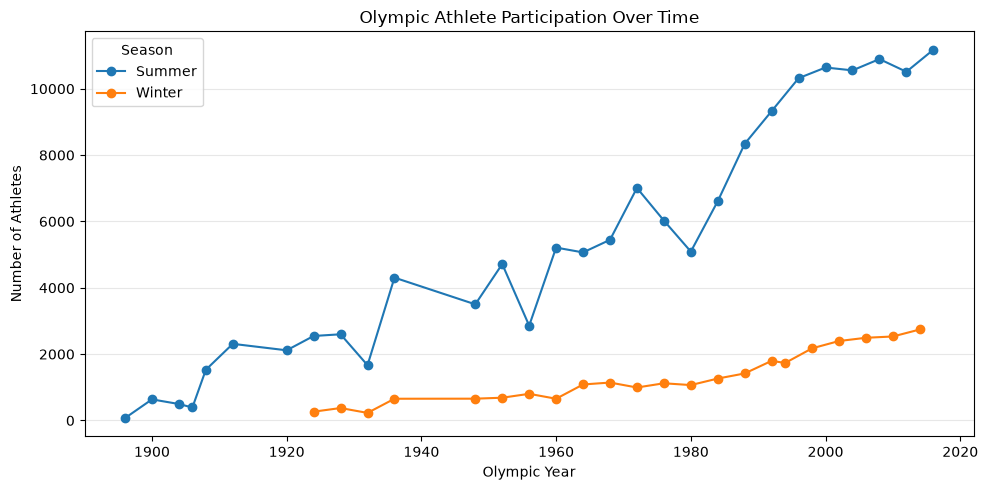

In [5]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 5))

for season, group in df_participation.groupby("season"):
    group = group.sort_values("games_year")

    ax.plot(
        group["games_year"],
        group["total_athletes"],
        marker="o",
        label=season
    )

ax.set_title("Olympic Athlete Participation Over Time")
ax.set_xlabel("Olympic Year")
ax.set_ylabel("Number of Athletes")
ax.legend(title="Season")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [8]:
df_participation.to_csv(
    "olympics_participation.csv",
    index=False
)

In [6]:
q1 = """
WITH editions AS (
    SELECT
        games_year,
        season,
        COUNT(*) AS edition_records
    FROM public.games
    GROUP BY games_year, season
)
SELECT
    games_year,
    season,
    edition_records,
    games_year - LAG(games_year) OVER (
        PARTITION BY season
        ORDER BY games_year
    ) AS years_since_previous_same_season
FROM editions
ORDER BY games_year, season;
"""

df_q1 = sql(q1)
df_q1

,games_year,season,edition_records,years_since_previous_same_season
0,1896,Summer,1,NaN
1,1900,Summer,1,4.0
2,1904,Summer,1,4.0
3,1906,Summer,1,2.0
4,1908,Summer,1,2.0
5,1912,Summer,1,4.0
6,1920,Summer,1,8.0
7,1924,Summer,1,4.0
8,1924,Winter,1,NaN
9,1928,Summer,1,4.0


In [7]:
q2 = """
SELECT
    g.games_year,
    g.season,
    COUNT(DISTINCT e.id) AS number_of_events,
    COUNT(DISTINCT gc.id) AS competitor_entries,
    COUNT(DISTINCT gc.person_id) AS unique_participants
FROM public.games g
LEFT JOIN public.games_competitor gc
    ON g.id = gc.games_id
LEFT JOIN public.competitor_event ce
    ON gc.id = ce.competitor_id
LEFT JOIN public.event e
    ON ce.event_id = e.id
GROUP BY
    g.id,
    g.games_year,
    g.season
ORDER BY
    g.games_year,
    g.season;
"""

df_q2 = sql(q2)
df_q2

,games_year,season,number_of_events,competitor_entries,unique_participants
0,1896,Summer,42,72,72
1,1900,Summer,90,636,636
2,1904,Summer,94,496,496
3,1906,Summer,72,391,391
4,1908,Summer,109,1529,1529
5,1912,Summer,107,2310,2310
6,1920,Summer,153,2115,2115
7,1924,Summer,131,2547,2547
8,1924,Winter,17,265,265
9,1928,Summer,122,2598,2598


In [8]:
q3 = """
SELECT
    g.games_year,
    g.season,
    g.games_name,
    c.city_name,
    COUNT(DISTINCT gc.person_id) AS unique_participants,
    COUNT(DISTINCT e.id) AS number_of_events,
    COUNT(DISTINCT ce.competitor_id) AS competitor_event_entries
FROM public.games g
LEFT JOIN public.games_city gci
    ON g.id = gci.games_id
LEFT JOIN public.city c
    ON gci.city_id = c.id
LEFT JOIN public.games_competitor gc
    ON g.id = gc.games_id
LEFT JOIN public.competitor_event ce
    ON gc.id = ce.competitor_id
LEFT JOIN public.event e
    ON ce.event_id = e.id
GROUP BY
    g.id,
    g.games_year,
    g.season,
    g.games_name,
    c.city_name
ORDER BY
    g.games_year,
    g.season;
"""

df_q3 = sql(q3)
df_q3

,games_year,season,games_name,city_name,unique_participants,number_of_events,competitor_event_entries
0,1896,Summer,1896 Summer,Athina,72,42,72
1,1900,Summer,1900 Summer,Paris,636,90,636
2,1904,Summer,1904 Summer,St. Louis,496,94,496
3,1906,Summer,1906 Summer,Athina,391,72,391
4,1908,Summer,1908 Summer,London,1529,109,1529
5,1912,Summer,1912 Summer,Stockholm,2310,107,2310
6,1920,Summer,1920 Summer,Antwerpen,2115,153,2115
7,1924,Summer,1924 Summer,Paris,2547,131,2547
8,1924,Winter,1924 Winter,Chamonix,265,17,265
9,1928,Summer,1928 Summer,Amsterdam,2598,122,2598


In [9]:
q4 = """
SELECT
    s.sport_name,
    MIN(g.games_year) AS first_edition_year,
    MAX(g.games_year) AS latest_edition_year,
    COUNT(DISTINCT g.id) AS editions_present,
    COUNT(DISTINCT e.id) AS total_distinct_events
FROM public.sport s
JOIN public.event e
    ON s.id = e.sport_id
JOIN public.competitor_event ce
    ON e.id = ce.event_id
JOIN public.games_competitor gc
    ON ce.competitor_id = gc.id
JOIN public.games g
    ON gc.games_id = g.id
GROUP BY
    s.id,
    s.sport_name
ORDER BY
    latest_edition_year DESC,
    first_edition_year DESC;
"""

df_q4 = sql(q4)
df_q4

,sport_name,first_edition_year,latest_edition_year,editions_present,total_distinct_events
0,Rugby Sevens,2016,2016,1,2
1,Taekwondo,2000,2016,5,8
2,Triathlon,2000,2016,5,2
3,Trampolining,2000,2016,5,2
4,Beach Volleyball,1996,2016,6,2
...,...,...,...,...,...
61,Lacrosse,1904,1908,2,1
62,Roque,1904,1904,1,1
63,Cricket,1900,1900,1,1
64,Croquet,1900,1900,1,3


In [10]:
q5 = """
SELECT
    g.games_year,
    g.season,
    s.sport_name,
    COUNT(DISTINCT gc.person_id) AS unique_participants,
    COUNT(DISTINCT e.id) AS number_of_events,
    COUNT(DISTINCT ce.competitor_id) AS competitor_event_entries
FROM public.games g
JOIN public.games_competitor gc
    ON g.id = gc.games_id
JOIN public.competitor_event ce
    ON gc.id = ce.competitor_id
JOIN public.event e
    ON ce.event_id = e.id
JOIN public.sport s
    ON e.sport_id = s.id
GROUP BY
    g.games_year,
    g.season,
    s.id,
    s.sport_name
ORDER BY
    s.sport_name,
    g.games_year;
"""

df_q5 = sql(q5)
df_q5

,games_year,season,sport_name,unique_participants,number_of_events,competitor_event_entries
0,1936,Summer,Aeronautics,1,1,1
1,1936,Winter,Alpine Skiing,102,2,102
2,1948,Winter,Alpine Skiing,164,6,164
3,1952,Winter,Alpine Skiing,165,6,165
4,1956,Winter,Alpine Skiing,172,6,172
...,...,...,...,...,...,...
901,2000,Summer,Wrestling,314,16,314
902,2004,Summer,Wrestling,342,18,342
903,2008,Summer,Wrestling,343,18,343
904,2012,Summer,Wrestling,339,18,339


In [11]:
q6 = """
SELECT
    nr.region_name,
    s.sport_name,
    COUNT(DISTINCT p.id) AS unique_participants,
    COUNT(DISTINCT g.id) AS editions_participated,
    COUNT(DISTINCT ce.event_id) AS distinct_events
FROM public.person p
JOIN public.person_region pr
    ON p.id = pr.person_id
JOIN public.noc_region nr
    ON pr.region_id = nr.id
JOIN public.games_competitor gc
    ON p.id = gc.person_id
JOIN public.games g
    ON gc.games_id = g.id
JOIN public.competitor_event ce
    ON gc.id = ce.competitor_id
JOIN public.event e
    ON ce.event_id = e.id
JOIN public.sport s
    ON e.sport_id = s.id
GROUP BY
    nr.id,
    nr.region_name,
    s.id,
    s.sport_name
ORDER BY
    s.sport_name,
    unique_participants DESC;
"""

df_q6 = sql(q6)
df_q6

,region_name,sport_name,unique_participants,editions_participated,distinct_events
0,Switzerland,Aeronautics,1,1,1
1,USA,Alpine Skiing,177,19,10
2,Switzerland,Alpine Skiing,175,19,10
3,Austria,Alpine Skiing,170,19,10
4,France,Alpine Skiing,166,19,10
...,...,...,...,...,...
3965,Boliva,Wrestling,1,1,1
3966,Nicaragua,Wrestling,1,1,1
3967,Bahrain,Wrestling,1,1,1
3968,Chile,Wrestling,1,1,1


In [12]:
eda_results = {
    "Q1_Games_Frequency": df_q1,
    "Q2_Games_Scale": df_q2,
    "Q3_Notable_Editions": df_q3,
    "Q4_Emerging_Sports": df_q4,
    "Q5_Sport_Trends": df_q5,
    "Q6_Regional_Sports": df_q6,
}

with pd.ExcelWriter("olympics_eda.xlsx", engine="openpyxl") as writer:
    for sheet_name, df in eda_results.items():
        df.to_excel(
            writer,
            sheet_name=sheet_name,
            index=False
        )

In [13]:
q7 = """
WITH event_gender AS (
    SELECT
        s.sport_name,
        e.id AS event_id,
        CASE
            WHEN e.event_name ILIKE '%women%'
                 AND e.event_name ILIKE '%men%'
                THEN 'Mixed / Combined'
            WHEN e.event_name ILIKE '%women%'
                THEN 'Women'
            WHEN e.event_name ILIKE '%men%'
                THEN 'Men'
            ELSE 'Unspecified'
        END AS gender_category
    FROM public.event e
    JOIN public.sport s
        ON e.sport_id = s.id
)
SELECT
    sport_name,
    gender_category,
    COUNT(DISTINCT event_id) AS number_of_events
FROM event_gender
GROUP BY sport_name, gender_category
ORDER BY sport_name, gender_category;
"""

df_q7 = sql(q7)
df_q7



q8 = """
SELECT
    s.sport_name,
    e.event_name,
    MIN(g.games_year) AS first_observed_year,
    MAX(g.games_year) AS latest_observed_year,
    COUNT(DISTINCT g.id) AS editions_present
FROM public.event e
JOIN public.sport s
    ON e.sport_id = s.id
JOIN public.competitor_event ce
    ON e.id = ce.event_id
JOIN public.games_competitor gc
    ON ce.competitor_id = gc.id
JOIN public.games g
    ON gc.games_id = g.id
GROUP BY
    s.sport_name,
    e.id,
    e.event_name
ORDER BY
    first_observed_year DESC,
    s.sport_name,
    e.event_name;
"""

df_q8 = sql(q8)
df_q8




q9 = """
WITH event_history AS (
    SELECT
        s.sport_name,
        e.id AS event_id,
        e.event_name,
        MIN(g.games_year) AS first_observed_year,
        MAX(g.games_year) AS last_observed_year,
        COUNT(DISTINCT g.id) AS editions_present
    FROM public.event e
    JOIN public.sport s
        ON e.sport_id = s.id
    JOIN public.competitor_event ce
        ON e.id = ce.event_id
    JOIN public.games_competitor gc
        ON ce.competitor_id = gc.id
    JOIN public.games g
        ON gc.games_id = g.id
    GROUP BY
        s.sport_name,
        e.id,
        e.event_name
),
latest_year AS (
    SELECT MAX(games_year) AS max_year
    FROM public.games
)
SELECT
    eh.sport_name,
    eh.event_name,
    eh.first_observed_year,
    eh.last_observed_year,
    eh.editions_present,
    ly.max_year AS latest_dataset_year
FROM event_history eh
CROSS JOIN latest_year ly
WHERE eh.last_observed_year < ly.max_year
ORDER BY
    eh.last_observed_year DESC,
    eh.sport_name,
    eh.event_name;
"""

df_q9 = sql(q9)
df_q9





q10 = """
SELECT
    g.games_year,
    g.season,
    p.gender,
    COUNT(DISTINCT p.id) AS participants_with_measurements,
    ROUND(AVG(NULLIF(p.height, 0))::numeric, 2)
        AS average_height_cm,
    ROUND(AVG(NULLIF(p.weight, 0))::numeric, 2)
        AS average_weight_kg,
    ROUND(
        PERCENTILE_CONT(0.5) WITHIN GROUP (
            ORDER BY NULLIF(p.height, 0)
        )::numeric,
        2
    ) AS median_height_cm,
    ROUND(
        PERCENTILE_CONT(0.5) WITHIN GROUP (
            ORDER BY NULLIF(p.weight, 0)
        )::numeric,
        2
    ) AS median_weight_kg
FROM public.games g
JOIN public.games_competitor gc
    ON g.id = gc.games_id
JOIN public.person p
    ON gc.person_id = p.id
WHERE p.height > 0
   OR p.weight > 0
GROUP BY
    g.games_year,
    g.season,
    p.gender
ORDER BY
    g.games_year,
    g.season,
    p.gender;
"""

df_q10 = sql(q10)
df_q10





q11 = """
SELECT
    nr.region_name,
    s.sport_name,
    COUNT(*) AS medal_awards,
    COUNT(*) FILTER (
        WHERE m.medal_name = 'Gold'
    ) AS gold_medals,
    COUNT(*) FILTER (
        WHERE m.medal_name = 'Silver'
    ) AS silver_medals,
    COUNT(*) FILTER (
        WHERE m.medal_name = 'Bronze'
    ) AS bronze_medals
FROM public.competitor_event ce
JOIN public.medal m
    ON ce.medal_id = m.id
JOIN public.games_competitor gc
    ON ce.competitor_id = gc.id
JOIN public.person p
    ON gc.person_id = p.id
JOIN public.person_region pr
    ON p.id = pr.person_id
JOIN public.noc_region nr
    ON pr.region_id = nr.id
JOIN public.event e
    ON ce.event_id = e.id
JOIN public.sport s
    ON e.sport_id = s.id
WHERE m.medal_name IS NOT NULL
GROUP BY
    nr.id,
    nr.region_name,
    s.id,
    s.sport_name
ORDER BY
    s.sport_name,
    medal_awards DESC;
"""

df_q11 = sql(q11)
df_q11





q12 = """
WITH participant_performance AS (
    SELECT
        nr.region_name,
        s.sport_name,
        p.gender,
        CASE
            WHEN gc.age < 20 THEN 'Under 20'
            WHEN gc.age BETWEEN 20 AND 24 THEN '20-24'
            WHEN gc.age BETWEEN 25 AND 29 THEN '25-29'
            WHEN gc.age BETWEEN 30 AND 34 THEN '30-34'
            ELSE '35 and above'
        END AS age_group,
        CASE
            WHEN m.medal_name IS NOT NULL THEN 1
            ELSE 0
        END AS won_medal
    FROM public.competitor_event ce
    JOIN public.games_competitor gc
        ON ce.competitor_id = gc.id
    JOIN public.person p
        ON gc.person_id = p.id
    JOIN public.person_region pr
        ON p.id = pr.person_id
    JOIN public.noc_region nr
        ON pr.region_id = nr.id
    JOIN public.event e
        ON ce.event_id = e.id
    JOIN public.sport s
        ON e.sport_id = s.id
    LEFT JOIN public.medal m
        ON ce.medal_id = m.id
)
SELECT
    region_name,
    sport_name,
    gender,
    age_group,
    COUNT(*) AS competitor_event_entries,
    SUM(won_medal) AS medal_winning_entries,
    ROUND(
        100.0 * SUM(won_medal) / NULLIF(COUNT(*), 0),
        2
    ) AS medal_entry_rate_pct
FROM participant_performance
GROUP BY
    region_name,
    sport_name,
    gender,
    age_group
HAVING COUNT(*) >= 20
ORDER BY
    medal_entry_rate_pct DESC,
    competitor_event_entries DESC;
"""

df_q12 = sql(q12)
df_q12

,region_name,sport_name,gender,age_group,competitor_event_entries,medal_winning_entries,medal_entry_rate_pct
0,USA,Basketball,M,20-24,117,117,100.0
1,Soviet Union,Ice Hockey,M,25-29,83,83,100.0
2,USA,Basketball,M,25-29,69,69,100.0
3,Soviet Union,Ice Hockey,M,20-24,56,56,100.0
4,USA,Ice Hockey,F,20-24,49,49,100.0
...,...,...,...,...,...,...,...
3377,Argentina,Cross Country Skiing,M,20-24,20,0,0.0
3378,Czech Republic,Nordic Combined,M,25-29,20,0,0.0
3379,Qatar,Athletics,M,Under 20,20,0,0.0
3380,China,Rowing,M,25-29,20,0,0.0


In [14]:
eda_results.update({
    "Q7_Gender_Events": df_q7,
    "Q8_New_Events": df_q8,
    "Q9_Event_History": df_q9,
    "Q10_Physical_Trends": df_q10,
    "Q11_Regional_Medals": df_q11,
    "Q12_Performance_Factors": df_q12,
})

In [15]:
# ============================================================
# Q13. Which regions consistently perform well across editions?
# ============================================================

q13 = """
WITH regional_medals AS (
    SELECT
        g.id AS games_id,
        g.games_year,
        g.season,
        nr.region_name,
        COUNT(*) AS medal_awards,
        COUNT(*) FILTER (
            WHERE m.medal_name = 'Gold'
        ) AS gold_medals
    FROM public.competitor_event ce
    JOIN public.medal m
        ON ce.medal_id = m.id
    JOIN public.games_competitor gc
        ON ce.competitor_id = gc.id
    JOIN public.games g
        ON gc.games_id = g.id
    JOIN public.person p
        ON gc.person_id = p.id
    JOIN public.person_region pr
        ON p.id = pr.person_id
    JOIN public.noc_region nr
        ON pr.region_id = nr.id
    WHERE m.medal_name IS NOT NULL
    GROUP BY
        g.id, g.games_year, g.season,
        nr.id, nr.region_name
)
SELECT
    region_name,
    season,
    COUNT(DISTINCT games_id) AS editions_with_medals,
    SUM(medal_awards) AS total_medal_awards,
    SUM(gold_medals) AS total_gold_medals,
    ROUND(AVG(medal_awards), 2) AS avg_medal_awards_per_medalling_edition
FROM regional_medals
GROUP BY region_name, season
ORDER BY
    editions_with_medals DESC,
    total_medal_awards DESC;
"""

df_q13 = sql(q13)


# ============================================================
# Q14. Which sports have higher medal counts from specific regions?
# ============================================================

q14 = """
SELECT
    nr.region_name,
    s.sport_name,
    COUNT(*) AS medal_awards,
    COUNT(*) FILTER (
        WHERE m.medal_name = 'Gold'
    ) AS gold_medals,
    COUNT(*) FILTER (
        WHERE m.medal_name = 'Silver'
    ) AS silver_medals,
    COUNT(*) FILTER (
        WHERE m.medal_name = 'Bronze'
    ) AS bronze_medals
FROM public.competitor_event ce
JOIN public.medal m
    ON ce.medal_id = m.id
JOIN public.games_competitor gc
    ON ce.competitor_id = gc.id
JOIN public.person p
    ON gc.person_id = p.id
JOIN public.person_region pr
    ON p.id = pr.person_id
JOIN public.noc_region nr
    ON pr.region_id = nr.id
JOIN public.event e
    ON ce.event_id = e.id
JOIN public.sport s
    ON e.sport_id = s.id
WHERE m.medal_name IS NOT NULL
GROUP BY
    nr.id, nr.region_name,
    s.id, s.sport_name
ORDER BY
    s.sport_name,
    medal_awards DESC;
"""

df_q14 = sql(q14)


# ============================================================
# Q15. What are some unexpected or surprising medal wins?
# Identify first-time medal-winning regions by sport.
# ============================================================

q15 = """
WITH regional_sport_medals AS (
    SELECT
        g.id AS games_id,
        g.games_year,
        g.season,
        nr.region_name,
        s.sport_name,
        COUNT(*) AS medal_awards,
        COUNT(*) FILTER (
            WHERE m.medal_name = 'Gold'
        ) AS gold_medals
    FROM public.competitor_event ce
    JOIN public.medal m
        ON ce.medal_id = m.id
    JOIN public.games_competitor gc
        ON ce.competitor_id = gc.id
    JOIN public.games g
        ON gc.games_id = g.id
    JOIN public.person p
        ON gc.person_id = p.id
    JOIN public.person_region pr
        ON p.id = pr.person_id
    JOIN public.noc_region nr
        ON pr.region_id = nr.id
    JOIN public.event e
        ON ce.event_id = e.id
    JOIN public.sport s
        ON e.sport_id = s.id
    WHERE m.medal_name IS NOT NULL
    GROUP BY
        g.id, g.games_year, g.season,
        nr.id, nr.region_name,
        s.id, s.sport_name
),
first_medal AS (
    SELECT
        *,
        ROW_NUMBER() OVER (
            PARTITION BY region_name, sport_name, season
            ORDER BY games_year, games_id
        ) AS medal_appearance_number
    FROM regional_sport_medals
)
SELECT
    games_year,
    season,
    region_name,
    sport_name,
    medal_awards,
    gold_medals
FROM first_medal
WHERE medal_appearance_number = 1
ORDER BY games_year DESC, gold_medals DESC, medal_awards DESC;
"""

df_q15 = sql(q15)


# ============================================================
# Q16. Which regions experienced growth or decline in participation?
# ============================================================

q16 = """
WITH regional_participation AS (
    SELECT
        g.id AS games_id,
        g.games_year,
        g.season,
        nr.region_name,
        COUNT(DISTINCT gc.person_id) AS participants
    FROM public.games g
    JOIN public.games_competitor gc
        ON g.id = gc.games_id
    JOIN public.person p
        ON gc.person_id = p.id
    JOIN public.person_region pr
        ON p.id = pr.person_id
    JOIN public.noc_region nr
        ON pr.region_id = nr.id
    GROUP BY
        g.id, g.games_year, g.season,
        nr.id, nr.region_name
),
participation_changes AS (
    SELECT
        *,
        LAG(participants) OVER (
            PARTITION BY region_name, season
            ORDER BY games_year, games_id
        ) AS previous_edition_participants
    FROM regional_participation
)
SELECT
    games_year,
    season,
    region_name,
    participants,
    previous_edition_participants,
    participants - previous_edition_participants AS participant_change,
    ROUND(
        100.0 * (participants - previous_edition_participants)
        / NULLIF(previous_edition_participants, 0),
        2
    ) AS participant_change_pct
FROM participation_changes
ORDER BY games_year, season, region_name;
"""

df_q16 = sql(q16)


# ============================================================
# Q17. How might geography or culture relate to sports performance?
# Compare regional participation and medal outcomes by sport.
# ============================================================

q17 = """
SELECT
    nr.region_name,
    s.sport_name,
    COUNT(DISTINCT gc.person_id) AS unique_participants,
    COUNT(DISTINCT gc.games_id) AS editions_participated,
    COUNT(*) AS competitor_event_entries,
    COUNT(*) FILTER (
        WHERE m.medal_name IS NOT NULL
    ) AS medal_winning_entries,
    ROUND(
        100.0 * COUNT(*) FILTER (
            WHERE m.medal_name IS NOT NULL
        ) / NULLIF(COUNT(*), 0),
        2
    ) AS medal_entry_rate_pct
FROM public.games_competitor gc
JOIN public.person p
    ON gc.person_id = p.id
JOIN public.person_region pr
    ON p.id = pr.person_id
JOIN public.noc_region nr
    ON pr.region_id = nr.id
JOIN public.competitor_event ce
    ON gc.id = ce.competitor_id
JOIN public.event e
    ON ce.event_id = e.id
JOIN public.sport s
    ON e.sport_id = s.id
LEFT JOIN public.medal m
    ON ce.medal_id = m.id
GROUP BY
    nr.id, nr.region_name,
    s.id, s.sport_name
HAVING COUNT(*) >= 20
ORDER BY
    s.sport_name,
    medal_entry_rate_pct DESC;
"""

df_q17 = sql(q17)


# ============================================================
# Q18. Which regions have had the greatest overall medal impact?
# ============================================================

q18 = """
SELECT
    nr.region_name,
    COUNT(*) AS total_medal_awards,
    COUNT(*) FILTER (
        WHERE m.medal_name = 'Gold'
    ) AS gold_medals,
    COUNT(*) FILTER (
        WHERE m.medal_name = 'Silver'
    ) AS silver_medals,
    COUNT(*) FILTER (
        WHERE m.medal_name = 'Bronze'
    ) AS bronze_medals,
    COUNT(DISTINCT g.id) AS editions_with_medals,
    COUNT(DISTINCT s.id) AS sports_with_medals
FROM public.competitor_event ce
JOIN public.medal m
    ON ce.medal_id = m.id
JOIN public.games_competitor gc
    ON ce.competitor_id = gc.id
JOIN public.games g
    ON gc.games_id = g.id
JOIN public.person p
    ON gc.person_id = p.id
JOIN public.person_region pr
    ON p.id = pr.person_id
JOIN public.noc_region nr
    ON pr.region_id = nr.id
JOIN public.event e
    ON ce.event_id = e.id
JOIN public.sport s
    ON e.sport_id = s.id
WHERE m.medal_name IS NOT NULL
GROUP BY nr.id, nr.region_name
ORDER BY
    total_medal_awards DESC,
    gold_medals DESC;
"""

df_q18 = sql(q18)


# ============================================================
# Store Q13-Q18 results for the Excel workbook
# ============================================================

eda_results.update({
    "Q13_Consistent_Performance": df_q13,
    "Q14_Regional_Sport_Medals": df_q14,
    "Q15_First_Medal_Appearances": df_q15,
    "Q16_Participation_Changes": df_q16,
    "Q17_Regional_Sport_Performance": df_q17,
    "Q18_Overall_Medal_Impact": df_q18,
})


# ============================================================
# Preview all six DataFrames
# ============================================================

for question, df in {
    "Q13": df_q13,
    "Q14": df_q14,
    "Q15": df_q15,
    "Q16": df_q16,
    "Q17": df_q17,
    "Q18": df_q18,
}.items():
    print(f"\n{question}: {df.shape[0]} rows, {df.shape[1]} columns")
    display(df.head())


Q13: 195 rows, 6 columns


,region_name,season,editions_with_medals,total_medal_awards,total_gold_medals,avg_medal_awards_per_medalling_edition
0,UK,Summer,29,1889.0,617.0,65.14
1,Australia,Summer,29,1317.0,342.0,45.41
2,USA,Summer,28,4812.0,2374.0,171.86
3,France,Summer,28,1532.0,455.0,54.71
4,Denmark,Summer,28,592.0,179.0,21.14



Q14: 1506 rows, 6 columns


,region_name,sport_name,medal_awards,gold_medals,silver_medals,bronze_medals
0,Switzerland,Aeronautics,1,1,0,0
1,Austria,Alpine Skiing,114,34,39,41
2,Switzerland,Alpine Skiing,59,20,19,20
3,France,Alpine Skiing,45,15,15,15
4,USA,Alpine Skiing,41,16,17,8



Q15: 1516 rows, 6 columns


...

,games_year,season,region_name,participants,previous_edition_participants,participant_change,participant_change_pct
0,1896,Summer,Australia,1,NaN,NaN,NaN
1,1896,Summer,Austria,3,NaN,NaN,NaN
2,1896,Summer,Denmark,3,NaN,NaN,NaN
3,1896,Summer,France,9,NaN,NaN,NaN
4,1896,Summer,Germany,16,NaN,NaN,NaN



Q17: 1953 rows, 7 columns


,region_name,sport_name,unique_participants,editions_participated,competitor_event_entries,medal_winning_entries,medal_entry_rate_pct
0,Austria,Alpine Skiing,170,19,561,114,20.32
1,Switzerland,Alpine Skiing,175,19,521,59,11.32
2,Germany,Alpine Skiing,71,16,282,31,10.99
3,Croatia,Alpine Skiing,20,7,93,10,10.75
4,France,Alpine Skiing,166,19,481,45,9.36



Q18: 150 rows, 7 columns


,region_name,total_medal_awards,gold_medals,silver_medals,bronze_medals,editions_with_medals,sports_with_medals
0,USA,5414,2533,1580,1301,50,53
1,Soviet Union,2658,1135,783,740,29,35
2,Germany,2395,843,742,810,46,44
3,UK,1971,658,687,626,44,44
4,France,1686,492,563,631,49,45


In [16]:

# Create one Excel workbook containing Q1-Q18

eda_results = {
    "Q1_Games_Frequency": df_q1,
    "Q2_Games_Scale": df_q2,
    "Q3_Notable_Editions": df_q3,
    "Q4_Emerging_Sports": df_q4,
    "Q5_Sport_Trends": df_q5,
    "Q6_Regional_Sports": df_q6,
    "Q7_Gender_Events": df_q7,
    "Q8_New_Events": df_q8,
    "Q9_Event_History": df_q9,
    "Q10_Physical_Trends": df_q10,
    "Q11_Regional_Medals": df_q11,
    "Q12_Performance_Factors": df_q12,
    "Q13_Consistent_Performance": df_q13,
    "Q14_Regional_Sport_Medals": df_q14,
    "Q15_First_Medal_Appearances": df_q15,
    "Q16_Participation_Changes": df_q16,
    "Q17_Regional_Sport_Performance": df_q17,
    "Q18_Overall_Medal_Impact": df_q18,
}

output_file = "olympics_eda.xlsx"

with pd.ExcelWriter(output_file, engine="openpyxl") as writer:
    for sheet_name, df in eda_results.items():
        df.to_excel(
            writer,
            sheet_name=sheet_name,
            index=False
        )

print(f"Excel file created: {output_file}")
print(f"Total worksheets: {len(eda_results)}")

for sheet_name, df in eda_results.items():
    print(f"{sheet_name}: {len(df):,} rows, {len(df.columns)} columns")


Excel file created: olympics_eda.xlsx
Total worksheets: 18
Q1_Games_Frequency: 51 rows, 4 columns
Q2_Games_Scale: 51 rows, 5 columns
Q3_Notable_Editions: 52 rows, 7 columns
Q4_Emerging_Sports: 66 rows, 5 columns
Q5_Sport_Trends: 906 rows, 6 columns
Q6_Regional_Sports: 3,970 rows, 5 columns
Q7_Gender_Events: 120 rows, 3 columns
Q8_New_Events: 757 rows, 5 columns
Q9_Event_History: 451 rows, 6 columns
Q10_Physical_Trends: 96 rows, 8 columns
Q11_Regional_Medals: 1,506 rows, 6 columns
Q12_Performance_Factors: 3,382 rows, 7 columns
Q13_Consistent_Performance: 195 rows, 6 columns
Q14_Regional_Sport_Medals: 1,506 rows, 6 columns
Q15_First_Medal_Appearances: 1,516 rows, 6 columns
Q16_Participation_Changes: 4,069 rows, 7 columns
Q17_Regional_Sport_Performance: 1,953 rows, 7 columns
Q18_Overall_Medal_Impact: 150 rows, 7 columns
